# Checkpoint 2

Estimating the location and extent of slow conduction regions in the heart is a classic inverse problem in cardiac electrophysiology. In this checkpoint, you will use mathematical modeling and computational techniques to estimate the position and radius of slow conduction areas from activation times annotated on electrogram measurements (see Checkpoint 1).

A key tool for this task is the **eikonal equation**, a simplified model of cardiac electrophysiology that describes activation time as a function of spatial coordinates. The eikonal formulation provides a fast and efficient way to reconstruct activation patterns, making it well suited for PDE-constrained optimization, physics-informed neural networks, and the generation of in silico datasets for scientific machine learning.

Using one of these approaches, you will estimate the location and size of slow conduction regions—by minimizing the discrepancy between simulated and observed activation times.
You will also account for unknown tissue properties, including conduction velocity and anisotropy, which play a crucial role in wavefront propagation. The velocity of slow conduction areas is assumed to be common across all patients and therefore needs to be estimated only once.


In [1]:
# imports

import numpy as np
import matplotlib.pyplot as plt


# Physics-based model implementation

Implemenatation of the algorithm presented in :

Sermesant, Maxime, et al. "An anisotropic multi-front fast marching method for real-time simulation of cardiac electrophysiology." Functional Imaging and Modeling of the Heart: 4th International Conference, FIHM 2007, Salt Lake City, UT, USA, June 7-9, 2007. Proceedings 4. Springer Berlin Heidelberg, 2007.

In [2]:
import numpy as np
import heapq

def anisotropic_FMM_GPT(
    x0, y0, t0,
    X, Y,
    speed_input,
    sigma_11, sigma_12, sigma_22,
    N_edge=None
):
    """
    Fast-marching style solver with anisotropy and spatially varying speed.

    Parameters
    ----------
    x0, y0 : float
        Initial source location.
    t0 : float
        Initial activation time.
    X, Y : 2D ndarray
        Grid coordinates.
    speed_input : float, callable, or 2D ndarray
        Can be:
        - a scalar: constant speed everywhere
        - a function: speed_input(x, y)
        - a 2D array with same shape as X, Y
    sigma_11, sigma_12, sigma_22 : float
        Components of the inverse of conductivity tensor.
    N_edge : int or None
        Optional. If None, inferred from grid shape.

    Returns
    -------
    T_final : 2D ndarray
        Arrival time map.
    """

    nrows, ncols = X.shape
    if N_edge is None:
        N_edge = nrows - 1

    INF = 1e4
    P = np.linspace(0.0, 1.0, 11)

    # nearest grid node to source
    j0 = np.abs(X[0, :] - x0).argmin()
    i0 = np.abs(Y[:, 0] - y0).argmin()

    T = np.full((nrows, ncols), INF, dtype=float)
    T_final = np.full((nrows, ncols), INF, dtype=float)

    T[i0, j0] = t0
    T_final[i0, j0] = t0

    known = np.zeros((nrows, ncols), dtype=bool)

    # min-heap of (arrival_time, i, j)
    heap = [(t0, i0, j0)]

    def get_speed(i, j, x, y):
        if callable(speed_input):
            val = speed_input(x, y)
        elif np.isscalar(speed_input):
            val = speed_input
        else:
            val = speed_input[i, j]

        if val <= 0:
            raise ValueError(f"Speed must be positive. Got {val} at ({i}, {j}).")
        return val

    def metric_dist(xa, ya, xb, yb, speed_val):
        dx = xa - xb
        dy = ya - yb
        return np.sqrt(
            sigma_11 * dx * dx +
            2.0 * sigma_12 * dx * dy +
            sigma_22 * dy * dy
        ) / speed_val

    def update_fun(
        T_xi, T_x, T_y,
        X_xi, X_x, X_y,
        Y_xi, Y_x, Y_y,
        flag_known,
        i_xi, j_xi
    ):
        speed_val = get_speed(i_xi, j_xi, X_xi, Y_xi)

        if flag_known:
            dx = P * (X_xi - X_x) + (1.0 - P) * (X_xi - X_y)
            dy = P * (Y_xi - Y_x) + (1.0 - P) * (Y_xi - Y_y)

            triangle_vals = (
                P * T_x + (1.0 - P) * T_y
                + np.sqrt(
                    sigma_11 * dx * dx +
                    2.0 * sigma_12 * dx * dy +
                    sigma_22 * dy * dy
                ) / speed_val
            )
            cand = triangle_vals.min()
        else:
            cand = T_x + metric_dist(X_xi, Y_xi, X_x, Y_x, speed_val)

        return min(T_xi, cand)

    # side nodes used for triangle updates
    side_map = {
        (-1,  0): [(-1, +1), (-1, -1)],  # north
        (+1,  0): [(+1, +1), (+1, -1)],  # south
        ( 0, -1): [(+1, -1), (-1, -1)],  # west
        ( 0, +1): [(+1, +1), (-1, +1)],  # east
    }

    while heap:
        t_sel, i_sel, j_sel = heapq.heappop(heap)

        # ignore stale entries
        if known[i_sel, j_sel]:
            continue
        if t_sel > T_final[i_sel, j_sel]:
            continue

        known[i_sel, j_sel] = True

        # visit 4-neighbors
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, +1)]:
            ni, nj = i_sel + di, j_sel + dj

            if not (0 <= ni < nrows and 0 <= nj < ncols):
                continue
            if known[ni, nj]:
                continue

            new_T = INF

            for sdi, sdj in side_map[(di, dj)]:
                si, sj = i_sel + sdi, j_sel + sdj

                if not (0 <= si < nrows and 0 <= sj < ncols):
                    continue

                new_T = update_fun(
                    T_xi=new_T,
                    T_x=T_final[i_sel, j_sel],
                    T_y=T_final[si, sj],
                    X_xi=X[ni, nj], X_x=X[i_sel, j_sel], X_y=X[si, sj],
                    Y_xi=Y[ni, nj], Y_x=Y[i_sel, j_sel], Y_y=Y[si, sj],
                    flag_known=known[si, sj],
                    i_xi=ni, j_xi=nj
                )

            if new_T < T_final[ni, nj]:
                T[ni, nj] = new_T
                T_final[ni, nj] = new_T
                heapq.heappush(heap, (new_T, ni, nj))

    return T_final

# Eikonal equation

Let us consider the Eikonal model: find T(x,y)

\begin{aligned}
  & 80 \sqrt{ \nabla T(x,y) D \nabla T(x,y)} = 1  \,, \quad (x,y) \in [-2,2] \times [-2,2]\,,\\
  & u(x,y) = t_0,t_1  \,, \qquad \qquad \qquad \qquad \qquad x=x_0,x_1,y=y_0,y_1 \,, \\
\end{aligned}

where 
\begin{aligned}
D = 1\ \vec{b} \otimes \vec{b} + \frac{1}{a_{ratio}}  \ \vec{a} \otimes \vec{a},
\end{aligned}
being $ \vec{b} $ the given fiber orientation and $ \vec{a} $ the given cross-fiber orientation (orthogonal to $ \vec{b}$).

The unknown parameters of the problem are: 
- conduction velocity (tissue property common to all the patients),
- anisotropy ratio $a_{ratio}$ (patient specific tissue property),
- the slow conduction positions $(x_{SC},y_{SC})$ and its radius $r_{SC}$.

In [3]:
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0,2.0,401), np.linspace(-2.0,2.0,401))

x0 = -1.5
y0 = -1

theta_fiber = 0
a_ratio = 5

theta0 = np.pi/2 - theta_fiber
a = np.array([np.cos(theta0), np.sin(theta0)]).T
b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
print(D)

D_inv = np.linalg.inv(D)
sigma_11 = D_inv[0][0]
sigma_12 = D_inv[0][1]
sigma_21 = D_inv[1][0]
sigma_22 = D_inv[1][1]

xc, yc = 0.5, 0.5
r = 0.5

speed_field = lambda x, y: 20.0 if (x - xc)**2 + (y - yc)**2 <= r**2 else 80.0

activation_time = anisotropic_FMM_GPT( x0 , y0 , 0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )




[[1.0000000e+00 1.2246468e-17]
 [1.2246468e-17 2.0000000e-01]]


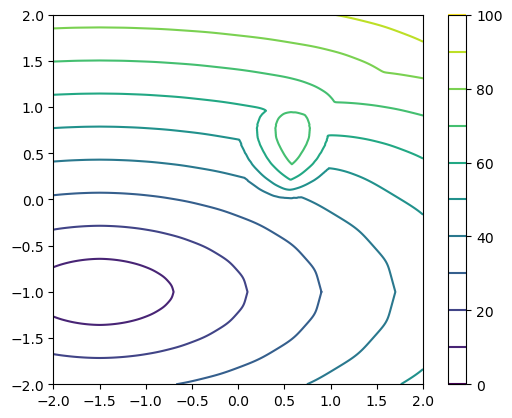

In [4]:

plt.contour(X_mesh, Y_mesh, activation_time*1000 , 10) 
plt.gca().set_aspect(1)
plt.colorbar()

In [5]:
N_samples = 1

np.random.seed(32)

measurements_dataset = []
groundtruth_dataset = []

for i_sample in range(N_samples):

    x0 = np.random.uniform(low=1.5,high=1.5)
    y0 = np.random.uniform(low=-1.5,high=1.5)
    x1 = np.random.uniform(low=1.5,high=1.5)
    y1 = np.random.uniform(low=-1.5,high=1.5)
    theta_fiber = 0.0
    a_ratio = np.random.uniform(low=1,high=9)

    theta0 = np.pi/2 - theta_fiber
    a = np.array([np.cos(theta0), np.sin(theta0)]).T
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

    D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
    print(D)

    D_inv = np.linalg.inv(D)
    sigma_11 = D_inv[0][0]
    sigma_12 = D_inv[0][1]
    sigma_21 = D_inv[1][0]
    sigma_22 = D_inv[1][1]

    # compute activation time
    activation_time = anisotropic_FMM_GPT( x0 , y0 , 0.0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )

    # rescaling in ms
    activation_time = activation_time*1e3

    # measurements location
    Spline_spacing = [0.5, 0.7, 1.3, 1.5]
    Angles_spacing =  [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5 ]
    
    index_extracted = []
    x_meas = []
    y_meas = []
    time_meas = []

    for i in range(4):
        #print(i)
        for j in range(5):
            #print(j)
            MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]) )**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]) )**2
            [i_sel, j_sel] = np.unravel_index(MeasMat.argmin(), MeasMat.shape) 
            index_extracted.append(i_sel)
            x_meas.append(X_mesh[i_sel,j_sel])
            y_meas.append(Y_mesh[i_sel,j_sel])
            time_meas.append(activation_time[i_sel,j_sel])

    measurements_dataset.append( [ x_meas, y_meas, time_meas ] )
    groundtruth_dataset.append([activation_time])

[[1.00000000e+00 8.88280440e-18]
 [8.88280440e-18 1.45067205e-01]]


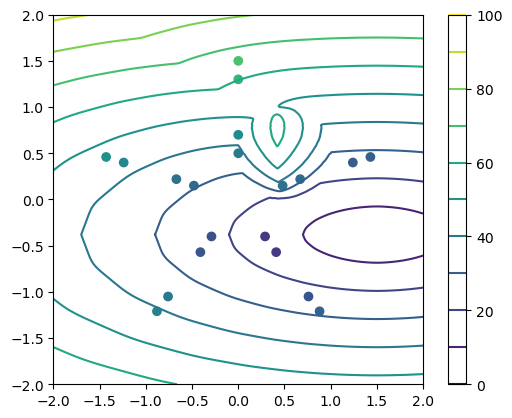

In [6]:
plt.figure(1)
plt.scatter( x_meas, y_meas, c=time_meas, vmin= 0, vmax=np.max(activation_time) )
plt.contour(X_mesh, Y_mesh, activation_time , 10)
plt.gca().set_aspect(1)
plt.colorbar()

# Checkpoint 2

Implement your algorithm to process the traces of the 20 unipolar electrogram signals and identify the center and radius of the slow conduction region.

The algorithm must return the following outputs:

1. **slow conduction center** 
2. **slow conduction radius**

Therefore output should be in the following form:
[x_SC,y_SC,r_SC] 

Provide your algorithm's implementation in this notebook usign the signature defined below.

In [7]:
# load data
signals = np.load('checkpoint2dataset.npy')

# select event to be display
ind_event = 0

signals_event = signals[ind_event,:,:]

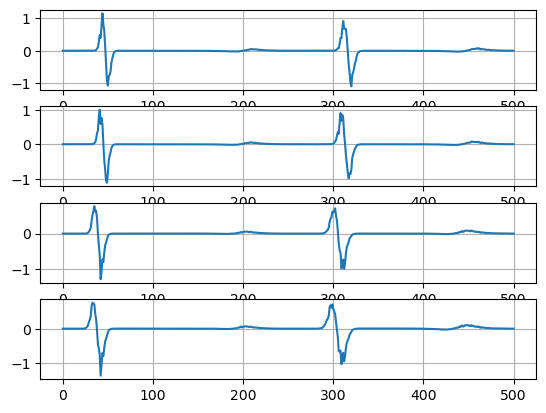

In [8]:
# select a spline (options: 0,1,2,3,4)
ind_spline = 0
# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

In [9]:
# known starting points (to test your algorithm)
# Note that a rescaling with respect to the center is needed
impulse_sites = np.load('checkpoint2FocalPoints.npy') -2.0
[x0,y0] = impulse_sites[0][0]
[x1,y1] = impulse_sites[0][1]

# t_0, t_1 can be extracted from the file: "checkpoint2starting.npy"

### signature of the function ###

In [14]:
import numpy as np
import scipy.signal as signal
import pickle

def GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1):
    
    # ---------------------------------------------------------
    # 1. CARICAMENTO DEL MODELLO E DEGLI SCALER
    # ---------------------------------------------------------
    # Carica il file fisico salvato precedentemente (deve essere nella stessa cartella)
    with open('consegna_cp2.pkl', 'rb') as f:
        pipeline = pickle.load(f)
        
    model = pipeline['model']
    scaler_X = pipeline['scaler_X']
    scaler_y = pipeline['scaler_y']

    # ---------------------------------------------------------
    # 2. ESTRAZIONE TEMPI DI ATTIVAZIONE (Dal CP1)
    # ---------------------------------------------------------
    num_sensors = signals_event.shape[0]
    fs = 1000.0 # 1 kHz
    
    # Filtro passa-basso (100 Hz cutoff) per pulire gli elettrogrammi grezzi
    nyquist = fs / 2.0
    b, a = signal.butter(N=3, Wn=(100.0 / nyquist), btype='low')
    
    raw_timings = []
    # Usiamo il tempo minimo tra i due stimoli come istante zero (t=0)
    t_pacing_base = min(t_0, t_1) 
    
    for i in range(num_sensors):
        sig = signals_event[i, :]
        sig_clean = signal.filtfilt(b, a, sig) 
        
        # dV/dt e ricerca del minimo (LAT)
        dvdt = np.gradient(sig_clean)
        idx_activation = np.argmin(dvdt)
        
        # Conversione in millisecondi e sottrazione del tempo di partenza
        time_ms_absolute = (idx_activation / fs) * 1000.0
        time_ms_relative = time_ms_absolute - t_pacing_base
        raw_timings.append(time_ms_relative)
        
    raw_timings = np.array(raw_timings)
    
    # ---------------------------------------------------------
    # 3. CORREZIONE GEOMETRICA DELLE SPLINE
    # ---------------------------------------------------------
    corrected_timings = []
    for s in range(5):  
        spline_segment = raw_timings[s*4 : (s+1)*4]
        # Invertiamo l'ordine dei sensori per allinearli al dataset sintetico [Vicino -> Lontano]
        spline_segment = spline_segment[::-1] 
        corrected_timings.extend(spline_segment)
    
    corrected_timings = np.array(corrected_timings)

    # ---------------------------------------------------------
    # 4. RISOLUZIONE DELLA SIMMETRIA DELLE SORGENTI
    # ---------------------------------------------------------
    # Impone che la sorgente con X minore sia sempre passata per prima alla rete
    if x_0 > x_1:
        x_0, y_0, x_1, y_1 = x_1, y_1, x_0, y_0

    # ---------------------------------------------------------
    # 5. ASSEMBLAGGIO E INFERENZA
    # ---------------------------------------------------------
    # Vettore da 24 feature: 20 tempi + 4 coordinate sorgenti (l'anisotropia è ignorata)
    input_features = np.zeros(24)
    input_features[:20] = corrected_timings - np.min(corrected_timings)
    input_features[20:24] = [x_0, y_0, x_1, y_1]
    input_features = input_features.reshape(1, -1)

    # Applica le normalizzazioni imparate durante il training
    input_scaled = scaler_X.transform(input_features)
    pred_scaled = model.predict(input_scaled)
    pred_physical = scaler_y.inverse_transform(pred_scaled)[0]
    
    x_SC = float(pred_physical[0])
    y_SC = float(pred_physical[1])
    
    # Vincolo fisico: il raggio non può collassare a zero o diventare enorme
    r_SC = float(np.clip(pred_physical[2], a_min=0.05, a_max=1.5))
        
    return [x_SC, y_SC, r_SC]

Caricamento del modello e dei dati per la valutazione spaziale...
Esecuzione inferenza sul Test Set Sintetico...
Errore Medio Assoluto (MAE) su Xc: 0.181
Errore Medio Assoluto (MAE) su Yc: 0.185
Errore Medio Assoluto (MAE) su Raggio: 0.073


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


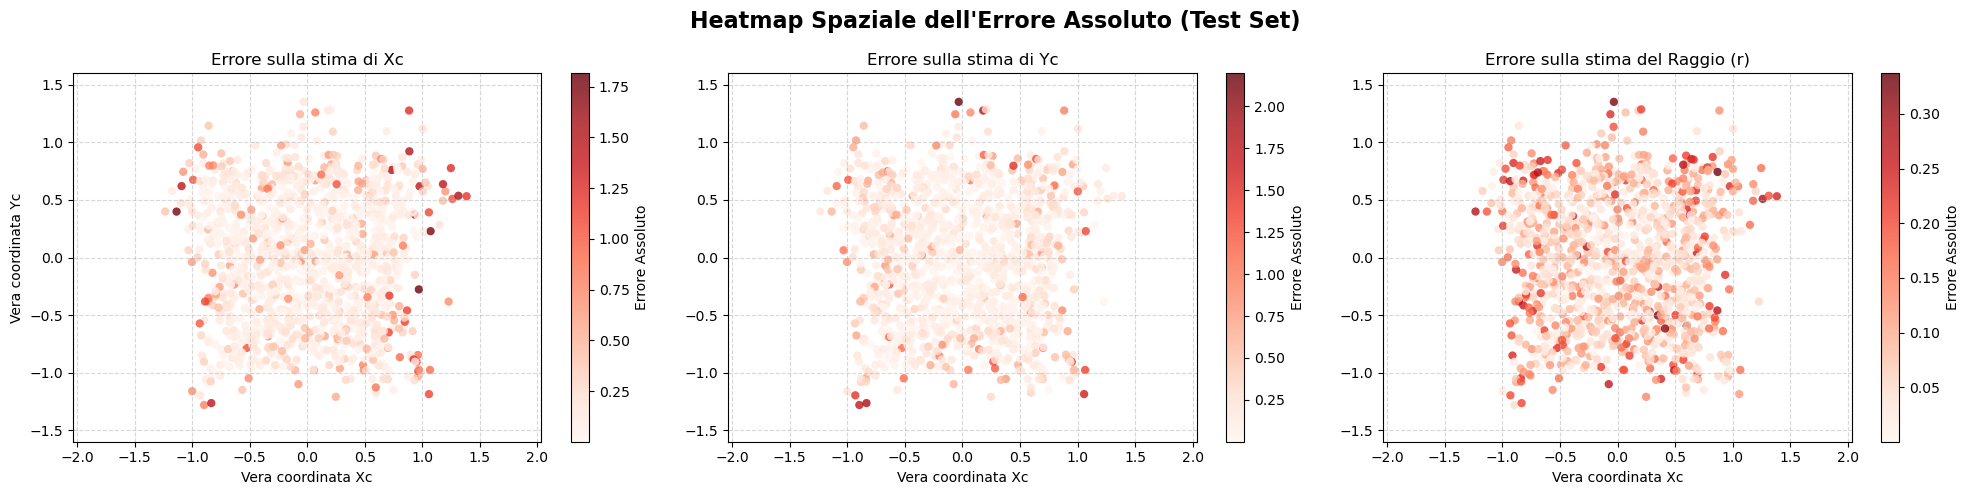

In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np
# import pickle
# from sklearn.model_selection import train_test_split

# print("Caricamento del modello e dei dati per la valutazione spaziale...")

# # 1. Carica il modello e gli scaler salvati per la consegna
# try:
#     with open('consegna_cp2.pkl', 'rb') as f:
#         pipeline = pickle.load(f)
#     model = pipeline['model']
#     scaler_y = pipeline['scaler_y']
#     scaler_X = pipeline['scaler_X']
# except FileNotFoundError:
#     raise FileNotFoundError("Errore: Impossibile trovare 'consegna_cp2.pkl'.")

# # 2. Carica il dataset sintetico per ottenere il Test Set (i Ground Truth)
# try:
#     with open('cardiac_dataset.pkl', 'rb') as f:
#         data = pickle.load(f)
    
#     X_raw = np.array(data['X']) 
#     y = np.array(data['Y'])

#     # Ricrea la stessa geometria applicata durante l'addestramento
#     for i in range(X_raw.shape[0]):
#         x0, y0, x1, y1 = X_raw[i, 20:24]
#         if x0 > x1:
#             X_raw[i, 20:24] = [x1, y1, x0, y0]
    
#     X = X_raw[:, :24] 
    
#     # Riapplica gli scaler caricati (è fondamentale usare transform, NON fit_transform qui)
#     X_scaled = scaler_X.transform(X)
#     y_scaled = scaler_y.transform(y)
    
#     # Estrai il test set usando lo stesso identico taglio (random_state=42)
#     _, X_test, _, y_test_scaled = train_test_split(X_scaled, y_scaled, test_size=0.15, random_state=42)
    
#     print("Esecuzione inferenza sul Test Set Sintetico...")
    
#     # 3. Predizioni e Calcolo Errore
#     y_pred_scaled = model.predict(X_test)
    
#     y_pred_physical = scaler_y.inverse_transform(y_pred_scaled)
#     y_true_physical = scaler_y.inverse_transform(y_test_scaled)
    
#     # Vincolo fisico
#     y_pred_physical[:, 2] = np.clip(y_pred_physical[:, 2], a_min=0.05, a_max=1.5)
    
#     err_xc = np.abs(y_true_physical[:, 0] - y_pred_physical[:, 0])
#     err_yc = np.abs(y_true_physical[:, 1] - y_pred_physical[:, 1])
#     err_r  = np.abs(y_true_physical[:, 2] - y_pred_physical[:, 2])
    
#     print(f"Errore Medio Assoluto (MAE) su Xc: {np.mean(err_xc):.3f}")
#     print(f"Errore Medio Assoluto (MAE) su Yc: {np.mean(err_yc):.3f}")
#     print(f"Errore Medio Assoluto (MAE) su Raggio: {np.mean(err_r):.3f}")
    
#     # 4. Creazione Heatmap
#     fig, axes = plt.subplots(1, 3, figsize=(20, 5))
#     fig.suptitle("Heatmap Spaziale dell'Errore Assoluto (Test Set)", fontsize=16, fontweight='bold')
    
#     X_true = y_true_physical[:, 0]
#     Y_true = y_true_physical[:, 1]
    
#     sc1 = axes[0].scatter(X_true, Y_true, c=err_xc, cmap='Reds', alpha=0.8, edgecolors='none')
#     axes[0].set_title('Errore sulla stima di Xc')
#     axes[0].set_xlabel('Vera coordinata Xc')
#     axes[0].set_ylabel('Vera coordinata Yc')
#     axes[0].axis('equal')
#     plt.colorbar(sc1, ax=axes[0], label='Errore Assoluto')
    
#     sc2 = axes[1].scatter(X_true, Y_true, c=err_yc, cmap='Reds', alpha=0.8, edgecolors='none')
#     axes[1].set_title('Errore sulla stima di Yc')
#     axes[1].set_xlabel('Vera coordinata Xc')
#     axes[1].axis('equal')
#     plt.colorbar(sc2, ax=axes[1], label='Errore Assoluto')
    
#     sc3 = axes[2].scatter(X_true, Y_true, c=err_r, cmap='Reds', alpha=0.8, edgecolors='none')
#     axes[2].set_title('Errore sulla stima del Raggio (r)')
#     axes[2].set_xlabel('Vera coordinata Xc')
#     axes[2].axis('equal')
#     plt.colorbar(sc3, ax=axes[2], label='Errore Assoluto')
    
#     for ax in axes:
#         ax.grid(True, linestyle='--', alpha=0.5)
#         ax.set_xlim(-1.6, 1.6)
#         ax.set_ylim(-1.6, 1.6)
    
#     plt.tight_layout()
#     plt.show()

# except Exception as e:
#     print(f"Si è verificato un errore: {e}")

Caricamento dati e modello per i 5 Test Cases...


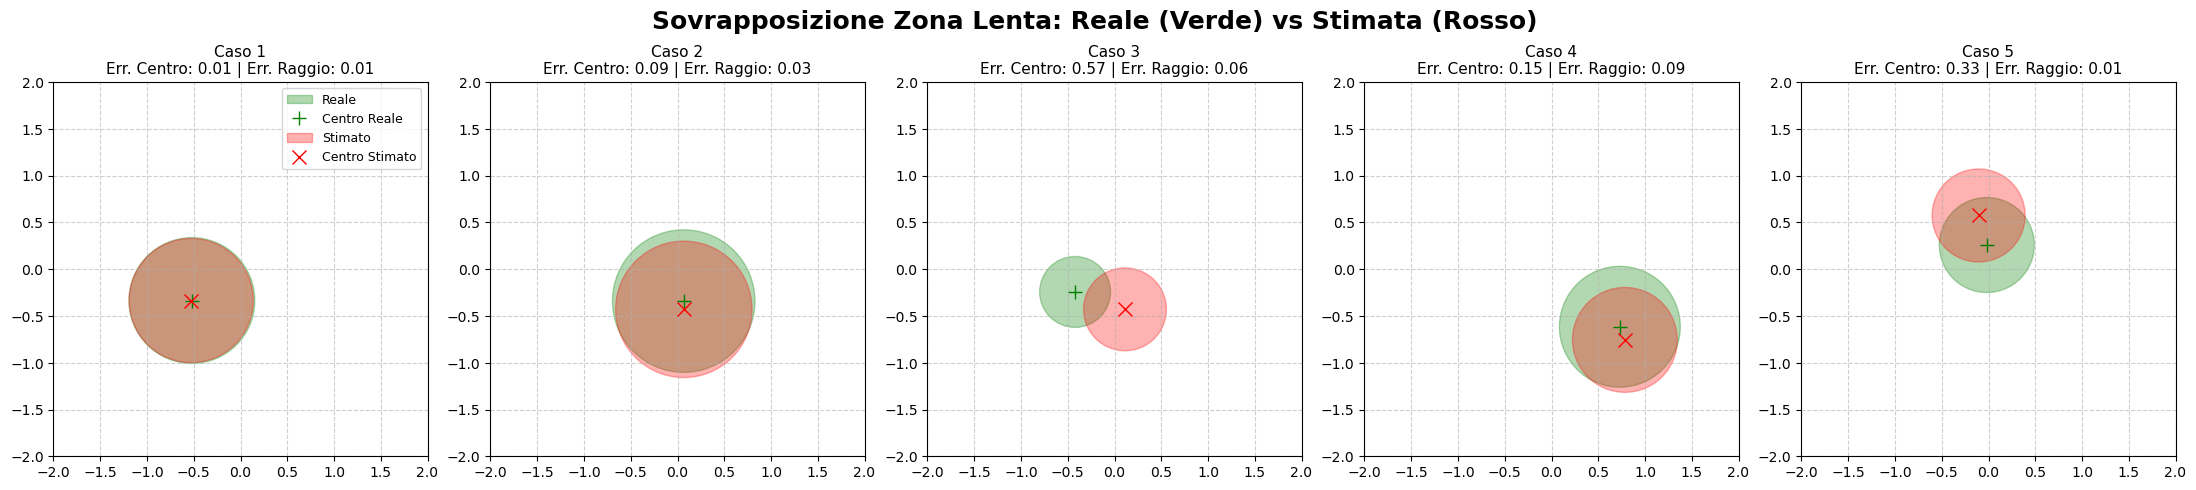

In [ ]:
# import matplotlib.pyplot as plt
# from matplotlib.patches import Circle
# import numpy as np
# import pickle
# from sklearn.model_selection import train_test_split

# print("Caricamento dati e modello per i 5 Test Cases...")

# # 1. Caricamento del modello addestrato
# try:
#     with open('consegna_cp2.pkl', 'rb') as f:
#         pipeline = pickle.load(f)
#     model = pipeline['model']
#     scaler_y = pipeline['scaler_y']
#     scaler_X = pipeline['scaler_X']
# except FileNotFoundError:
#     raise FileNotFoundError("Errore: Impossibile trovare 'consegna_cp2.pkl'.")

# # 2. Caricamento e preparazione esatta del Test Set
# with open('cardiac_dataset.pkl', 'rb') as f:
#     data = pickle.load(f)
    
# X_raw = np.array(data['X']) 
# y = np.array(data['Y'])

# # Risoluzione simmetria
# for i in range(X_raw.shape[0]):
#     x0, y0, x1, y1 = X_raw[i, 20:24]
#     if x0 > x1:
#         X_raw[i, 20:24] = [x1, y1, x0, y0]
        
# X = X_raw[:, :24] 
# X_scaled = scaler_X.transform(X)
# y_scaled = scaler_y.transform(y)

# # Estrazione del Test Set (usiamo seed 42 per coerenza)
# _, X_test, _, y_test_scaled = train_test_split(X_scaled, y_scaled, test_size=0.15, random_state=42)

# # 3. Selezioniamo 5 campioni per il test
# num_cases = 5
# X_cases = X_test[:num_cases]
# y_true_scaled = y_test_scaled[:num_cases]

# # 4. Inferenza e Denormalizzazione
# y_pred_scaled = model.predict(X_cases)

# y_true = scaler_y.inverse_transform(y_true_scaled)
# y_pred = scaler_y.inverse_transform(y_pred_scaled)

# # Applichiamo il vincolo di sicurezza sul raggio predetto
# y_pred[:, 2] = np.clip(y_pred[:, 2], a_min=0.05, a_max=1.5)

# # 5. Plotting delle sovrapposizioni (Cerchi 2D)
# fig, axes = plt.subplots(1, 5, figsize=(22, 5))
# fig.suptitle("Sovrapposizione Zona Lenta: Reale (Verde) vs Stimata (Rosso)", fontsize=18, fontweight='bold')

# for i in range(num_cases):
#     ax = axes[i]
    
#     # Valori Ground Truth
#     xc_t, yc_t, r_t = y_true[i]
#     # Valori Predetti
#     xc_p, yc_p, r_p = y_pred[i]
    
#     # Calcolo dell'errore spaziale (distanza tra i due centri)
#     dist_centri = np.sqrt((xc_t - xc_p)**2 + (yc_t - yc_p)**2)
#     err_raggio = abs(r_t - r_p)
    
#     # Disegno del cerchio REALE (Verde)
#     circle_true = Circle((xc_t, yc_t), r_t, color='green', alpha=0.3, label='Reale')
#     ax.add_patch(circle_true)
#     ax.plot(xc_t, yc_t, 'g+', markersize=10, label='Centro Reale') 
    
#     # Disegno del cerchio PREDETTO (Rosso)
#     circle_pred = Circle((xc_p, yc_p), r_p, color='red', alpha=0.3, label='Stimato')
#     ax.add_patch(circle_pred)
#     ax.plot(xc_p, yc_p, 'rx', markersize=10, label='Centro Stimato') 
    
#     # Impostazioni grafiche dell'asse
#     ax.set_xlim(-2.0, 2.0)
#     ax.set_ylim(-2.0, 2.0)
#     ax.set_aspect('equal') # Mantiene le proporzioni corrette, altrimenti i cerchi sembrano ellissi
#     ax.grid(True, linestyle='--', alpha=0.6)
    
#     ax.set_title(f"Caso {i+1}\nErr. Centro: {dist_centri:.2f} | Err. Raggio: {err_raggio:.2f}", fontsize=11)
    
#     # Aggiungi la legenda solo sul primo grafico per non riempire troppo spazio
#     if i == 0:
#         ax.legend(loc='upper right', fontsize=9)

# plt.tight_layout()
# plt.show()

Ricerca del Test Case con Raggio Minimo...
Trovato! Il raggio più piccolo nel test set è: 0.1077


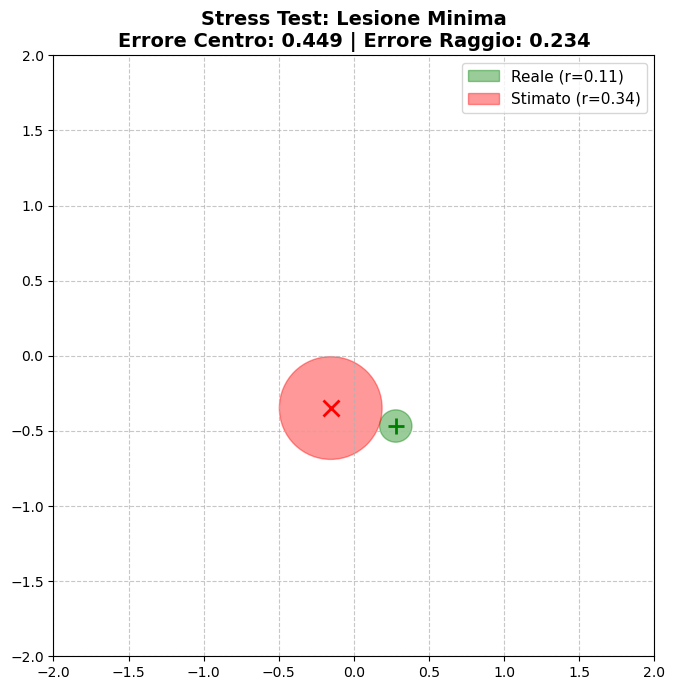

In [ ]:
# import matplotlib.pyplot as plt
# from matplotlib.patches import Circle
# import numpy as np
# import pickle
# from sklearn.model_selection import train_test_split

# print("Ricerca del Test Case con Raggio Minimo...")

# # 1. Caricamento ecosistema
# try:
#     with open('consegna_cp2.pkl', 'rb') as f:
#         pipeline = pickle.load(f)
#     model = pipeline['model']
#     scaler_y = pipeline['scaler_y']
#     scaler_X = pipeline['scaler_X']
# except FileNotFoundError:
#     raise FileNotFoundError("Errore: 'consegna_cp2.pkl' non trovato.")

# # 2. Caricamento Dati e Ingegneria delle Feature (esattamente come nel training)
# with open('cardiac_dataset.pkl', 'rb') as f:
#     data = pickle.load(f)
    
# X_raw = np.array(data['X']) 
# y = np.array(data['Y'])

# for i in range(X_raw.shape[0]):
#     # Simmetria
#     x0, y0, x1, y1 = X_raw[i, 20:24]
#     if x0 > x1:
#         X_raw[i, 20:24] = [x1, y1, x0, y0]
#     # Tempi Relativi
#     min_time = np.min(X_raw[i, :20])
#     X_raw[i, :20] = X_raw[i, :20] - min_time

# X = X_raw[:, :24] 
# X_scaled = scaler_X.transform(X)
# y_scaled = scaler_y.transform(y)

# # Estrazione Test Set
# _, X_test, _, y_test_scaled = train_test_split(X_scaled, y_scaled, test_size=0.15, random_state=42)

# # 3. TROVIAMO IL RAGGIO PIÙ PICCOLO NEL TEST SET
# y_test_physical = scaler_y.inverse_transform(y_test_scaled)
# raggi_reali = y_test_physical[:, 2]

# # Indice del raggio minimo
# idx_min_r = np.argmin(raggi_reali)
# raggio_minimo_reale = raggi_reali[idx_min_r]

# print(f"Trovato! Il raggio più piccolo nel test set è: {raggio_minimo_reale:.4f}")

# # 4. Estrazione di quel singolo caso e Inferenza
# X_single_case = X_test[idx_min_r].reshape(1, -1)
# y_true_single = y_test_physical[idx_min_r]

# y_pred_scaled = model.predict(X_single_case)
# y_pred_single = scaler_y.inverse_transform(y_pred_scaled)[0]

# # Vincolo fisico (clip)
# y_pred_single[2] = np.clip(y_pred_single[2], a_min=0.05, a_max=1.5)

# # 5. Grafico di Dettaglio
# fig, ax = plt.subplots(figsize=(7, 7))

# xc_t, yc_t, r_t = y_true_single
# xc_p, yc_p, r_p = y_pred_single

# dist_centri = np.sqrt((xc_t - xc_p)**2 + (yc_t - yc_p)**2)
# err_raggio = abs(r_t - r_p)

# # Disegno Realtà (Verde)
# circle_true = Circle((xc_t, yc_t), r_t, color='green', alpha=0.4, label=f'Reale (r={r_t:.2f})')
# ax.add_patch(circle_true)
# ax.plot(xc_t, yc_t, 'g+', markersize=12, markeredgewidth=2) 

# # Disegno Stima (Rosso)
# circle_pred = Circle((xc_p, yc_p), r_p, color='red', alpha=0.4, label=f'Stimato (r={r_p:.2f})')
# ax.add_patch(circle_pred)
# ax.plot(xc_p, yc_p, 'rx', markersize=12, markeredgewidth=2) 

# # Layout
# ax.set_xlim(-2.0, 2.0)
# ax.set_ylim(-2.0, 2.0)
# ax.set_aspect('equal')
# ax.grid(True, linestyle='--', alpha=0.7)

# ax.set_title(f"Stress Test: Lesione Minima\nErrore Centro: {dist_centri:.3f} | Errore Raggio: {err_raggio:.3f}", 
#              fontsize=14, fontweight='bold')
# ax.legend(loc='upper right', fontsize=11)

# plt.tight_layout()
# plt.show()